In [ ]:
import os
import zipfile
import glob

def explore_and_extract(folder_path):
    print(f"\n{'='*60}\nExploring: {folder_path}\n{'='*60}")


    zip_files = glob.glob(os.path.join(folder_path, "**/*.zip"), recursive=True)
    for z in zip_files:
        print(f"Extracting: {z}")
        with zipfile.ZipFile(z, 'r') as zf:
            zf.extractall(folder_path)

    all_files = glob.glob(os.path.join(folder_path, "**/*"), recursive=True)
    all_files = [f for f in all_files if os.path.isfile(f)]

    print(f"\nTotal files found: {len(all_files)}")
    extensions = {}
    for f in all_files:
        ext = os.path.splitext(f)[1].lower()
        extensions[ext] = extensions.get(ext, 0) + 1
    print("File types found:", extensions)

    print("\nFirst 10 file paths:")
    for f in all_files[:10]:
        print(" ", f)

    return all_files

emg_files = explore_and_extract("/content/emg")


Exploring: /content/emg

Total files found: 0
File types found: {}

First 10 file paths:


Extracting /content/semg_dataset.zip to /content/
Using file: /content/Whales1and2_Raw_Labelled/261124_SACLR_W4_5_S2_R15-2024-11-26_14-06-07.csv
All CSVs found: ['/content/Whales1and2_Raw_Labelled/261124_SACLR_W4_5_S2_R15-2024-11-26_14-06-07.csv', '/content/Whales1and2_Raw_Labelled/231124_45DBP_W12_5_S2_R16-2024-11-23_12-39-26.csv', '/content/Whales1and2_Raw_Labelled/291124_MTE_W18_S3_R13-2024-11-29_15-20-44.csv', '/content/Whales1and2_Raw_Labelled/261124_30DBP_W17_5_S2_R12-2024-11-26_13-27-55.csv', '/content/Whales1and2_Raw_Labelled/120125_30BP_W30_S1_R12-2025-01-12_07-40-23.csv', '/content/Whales1and2_Raw_Labelled/271124_CGCR_W52_S1_R15-2024-11-27_15-06-19.csv', '/content/Whales1and2_Raw_Labelled/291124_30DBP_W17_5_S1_R16-2024-11-29_14-41-39.csv', '/content/Whales1and2_Raw_Labelled/261124_SACLR_W4_5_S1_R30-2024-11-26_13-57-49.csv', '/content/Whales1and2_Raw_Labelled/261124_30DBP_W17_5_S2_17-2024-11-26_13-22-15.csv', '/content/Whales1and2_Raw_Labelled/291124_30DBP_W7_5_S2_R8-2024-11-2

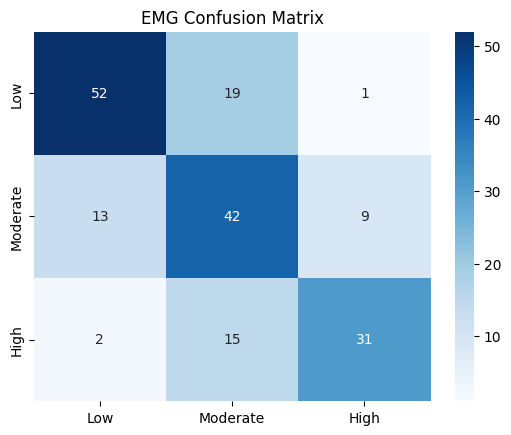


=== Feature Importance ===
emg_range    0.231221
emg_std      0.210669
emg_mean     0.209255
emg_rms      0.177104
emg_max      0.171750
dtype: float64


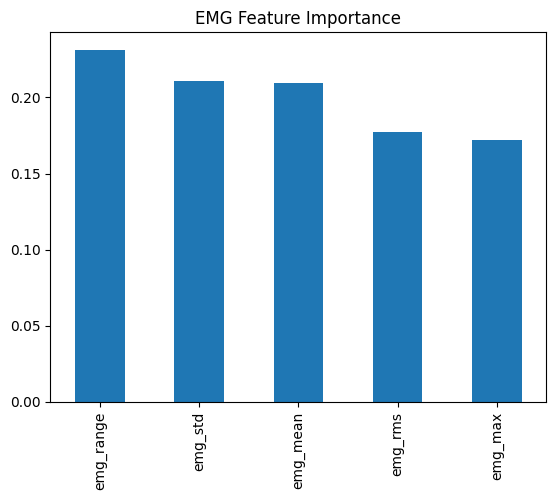


=== Value Ranges by CPOT Class ===
           emg_rms                        emg_mean                        \
               min         max       mean      min        max       mean   
cpot_class                                                                 
High         5.373  108.595001  85.565002    2.535  27.558001  22.096001   
Low          4.971   96.470001  28.039000    1.992  24.673000   8.418000   
Moderate     5.008  108.359001  61.473000    2.112  27.503000  16.405001   

           emg_std                        emg_max                         \
               min         max       mean     min        max        mean   
cpot_class                                                                 
High         4.738  105.040001  82.657997    15.0  460.48999  362.513000   
Low          4.483   93.261002  26.712999    15.0  408.98999  115.953003   
Moderate     4.541  104.810997  59.237999    15.0  459.48999  260.010010   

           emg_range                          
   

In [ ]:
import os, glob, zipfile
import pandas as pd

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


ZIP_FILE_PATH = "/content/semg_dataset.zip"
EXTRACT_ROOT = "/content/" # Extract to the /content/ directory

# The actual directory name created by the zip file within EXTRACT_ROOT
ACTUAL_EXTRACTED_DIR = "Whales1and2_Raw_Labelled"

# The full path to the extracted directory where CSVs are located
FOLDER = os.path.join(EXTRACT_ROOT, ACTUAL_EXTRACTED_DIR)

if os.path.exists(ZIP_FILE_PATH):
    # Check if the expected unzipped folder already exists to avoid re-extraction
    if not os.path.exists(FOLDER):
        print(f"Extracting {ZIP_FILE_PATH} to {EXTRACT_ROOT}")
        with zipfile.ZipFile(ZIP_FILE_PATH, 'r') as zf:
            zf.extractall(EXTRACT_ROOT) # Extract to the correct directory
    else:
        print(f"'{FOLDER}' already exists. Skipping extraction.")
else:
    raise FileNotFoundError(f"'{ZIP_FILE_PATH}' not found. Please ensure the dataset is uploaded.")


# Validate that the FOLDER now exists and contains CSVs
if not os.path.exists(FOLDER):
    raise FileNotFoundError(f"Expected CSV data folder '{FOLDER}' not found after extraction. Please check the zip file structure.")



csv_files = glob.glob(f"{FOLDER}/**/*.csv", recursive=True)
if not csv_files:
    raise FileNotFoundError(f"No CSV found under {FOLDER}. Run !find {FOLDER} to inspect manually.")
csv_files.sort(key=lambda f: os.path.getsize(f), reverse=True)
main_csv = csv_files[0]
print("Using file:", main_csv)
print("All CSVs found:", csv_files)

df = pd.read_csv(main_csv)
print("Columns:", list(df.columns))
print("Shape:", df.shape)


numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_like = ['id', 'label', 'class', 'subject', 'gesture', 'time', 'index']
signal_cols = [c for c in numeric_cols if not any(k in c.lower() for k in exclude_like)]
if not signal_cols:
    signal_cols = numeric_cols
print("Signal columns used:", signal_cols)

signal = df[signal_cols].values.astype(np.float32)

WINDOW = 50
n_windows = len(signal) // WINDOW
signal = signal[: n_windows * WINDOW].reshape(n_windows, WINDOW, len(signal_cols))

features = pd.DataFrame({
    "emg_rms": np.sqrt(np.mean(signal**2, axis=(1,2))),
    "emg_mean": np.mean(signal, axis=(1,2)),
    "emg_std": np.std(signal, axis=(1,2)),
    "emg_max": np.max(signal, axis=(1,2)),
    "emg_range": np.ptp(signal.reshape(n_windows, -1), axis=1),
})

np.random.seed(42)
combo = 0.5*features["emg_rms"] + 0.3*features["emg_std"] + 0.2*features["emg_range"]
combo_norm = (combo - combo.min()) / (combo.max() - combo.min() + 1e-8)
noise = np.random.normal(0, 0.18, size=len(combo_norm))
cpot_score = np.clip((combo_norm + noise) * 8, 0, 8)
cpot_class = pd.cut(cpot_score, bins=[-1,3,6,9], labels=["Low","Moderate","High"])


flip_idx = np.random.choice(len(cpot_class), size=int(0.10*len(cpot_class)), replace=False)
cpot_class = cpot_class.astype(object)
for i in flip_idx:
    cpot_class.iloc[i] = np.random.choice(["Low","Moderate","High"])

X = features
y = cpot_class


nan_mask = y.isna()
if nan_mask.any():
    print(f"Dropping {nan_mask.sum()} rows with NaN in target variable.")
    X = X[~nan_mask]
    y = y[~nan_mask]

y = y.astype(str)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=60, max_depth=4, min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)
preds = model.predict(X_test)

print("\n=== EMG Model Accuracy:", round(accuracy_score(y_test, preds), 3), "===")
print(classification_report(y_test, preds))

cm = confusion_matrix(y_test, preds, labels=["Low","Moderate","High"])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Low","Moderate","High"], yticklabels=["Low","Moderate","High"])
plt.title("EMG Confusion Matrix"); plt.show()

print("\n=== Feature Importance ===")
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance)
importance.plot(kind='bar', title="EMG Feature Importance"); plt.show()

print("\n=== Value Ranges by CPOT Class ===")
features["cpot_class"] = cpot_class
print(features.groupby("cpot_class").agg(['min','max','mean']).round(3))

joblib.dump(model, "emg_model.pkl")
print("\nSaved: emg_model.pkl")

In [ ]:
import os
print(os.listdir("/content"))

['.config', 'emg_model.pkl', 'semg_dataset.zip', 'Whales1and2_Raw_Labelled', 'sample_data']
